In [86]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from matplotlib.ticker import MaxNLocator

# https://matplotlib.org/stable/users/explain/colors/colormaps.html#qualitative


In [87]:
# read and process dataset

path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx"

df = pd.read_excel(path, sheet_name="TextReading_Included")
df = df[df.topic.notna()].reset_index(drop=True)
df.topic = df.topic.apply(lambda x: x.split(", "))
df.Year = df.Year.astype(int)

df_model = df[df.topic.apply(lambda x: "Model" in x)].reset_index(drop=True)

print(f"papers -- total: {df.shape[0]}")
print(f"papers -- new generative method : {df_model.shape[0]}")

papers -- total: 72
papers -- new generative method : 65


# *SUBSET DATASET COLUMNS*

# MODEL

In [88]:
import matplotlib.colors as mcolors

cmap = plt.cm.Set2
# cmap = plt.cm.Set3
# cmap = plt.cm.Paired
# cmap = plt.cm.Accent
# cmap = plt.cm.tab10
hex_colors = [
    mcolors.to_hex(c)
    for c in cmap.colors
]

print(hex_colors)

['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3', '#a6d854', '#ffd92f', '#e5c494', '#b3b3b3']


In [89]:
# plots
# MODEL_COLOR_MAP = {
#     'Autoregressive': 'tab:blue',
#     'Diffusion': 'tab:orange',
#     'Discriminative': 'tab:green',
#     'GAN': 'tab:red',
#     'Hybrid: Discriminative': 'tab:purple',
#     'Hybrid: Generative': 'tab:brown',
#     'VAE': 'tab:pink',
# }

# plots
MODEL_COLOR_MAP = {
    'Autoregressive': '#66c2a5',
    'Diffusion': '#fc8d62',
    'Discriminative': '#8da0cb',
    'GAN': '#e78ac3',
    'Hybrid: Discriminative': '#a6d854',
    'Hybrid: Generative': '#ffd92f',
    'VAE': '#e5c494',
}

In [90]:
# preprocessing
def process_model_df(df_model):

    df_model["Discriminative/Generative"] = df_model["Core Generative Paradigm"].apply(lambda x: "Discriminative" if "Discriminative" in x else "Generative")

    df_model["Model"] = \
    df_model["Core Generative Paradigm"].apply(lambda x: 
        "Hybrid: Discriminative" if ("Hybrid" in x and "Discriminative" in x) else 
        (
            "Hybrid: Generative" if "Hybrid" in x else x
        )
    )

    return df_model


def plot_discriminative_vs_generative(df_model):
    counts = df_model.groupby(['Year', 'Discriminative/Generative']).size().unstack(fill_value=0).sort_index()

    totals = counts.sum(axis=0)
    sorted_counts = (
        totals
        .sort_values(ascending=False)
        .index
    )
    counts = counts[sorted_counts]
    counts.columns = [
        f"{publisher} ({totals[publisher]})"
        for publisher in counts.columns
    ]

    # cmap = plt.cm.Set3
    cmap = plt.cm.tab20b
    # cmap = plt.cm.terrain
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    ax = counts.plot(
        kind='bar',
        stacked=True,
        rot=0,
        ylabel="# papers",
        color=colors,
    )


def plot_model_per_year(df_model):
    counts = df_model.groupby(['Year', 'Model']).size().unstack(fill_value=0).sort_index()
    
    colors = [
        MODEL_COLOR_MAP.get(col, "#cccccc")
        for col in counts.columns
    ]

    totals = counts.sum(axis=0)
    sorted_counts = (
        totals
        .sort_values(ascending=False)
        .index
    )
    counts = counts[sorted_counts]
    cols = counts.columns.to_list()
    counts.columns = [
        f"{publisher} ({totals[publisher]})"
        for publisher in cols
    ]

    ax = counts.plot(
        kind='bar',
        stacked=True,
        rot=0,
        ylabel="# papers",
        color=colors,
    )


def plot_model(df_model):    
    counts = df_model["Model"].value_counts(ascending=True)
    
    
    counts_col = counts.sort_index().index
    colors = [MODEL_COLOR_MAP[m] for m in reversed(counts_col)]

    # colors = [
    #     MODEL_COLOR_MAP.get(col, "#cccccc")
    #     for col in counts.index
    # ]

    ax = counts.plot(kind="barh", color=colors)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("# papers")
    ax.set_ylabel("ML model")

In [91]:
df_model = process_model_df(df_model)

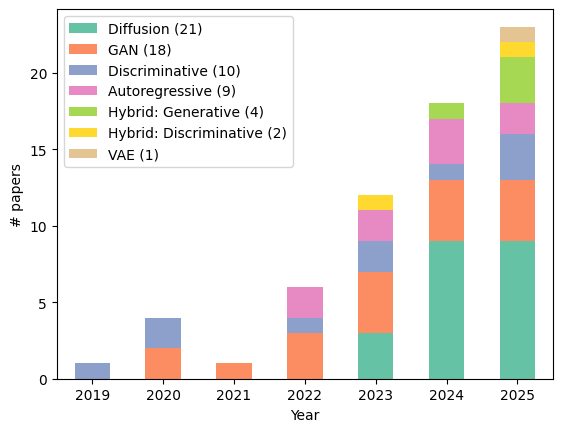

In [92]:
plot_model_per_year(df_model)

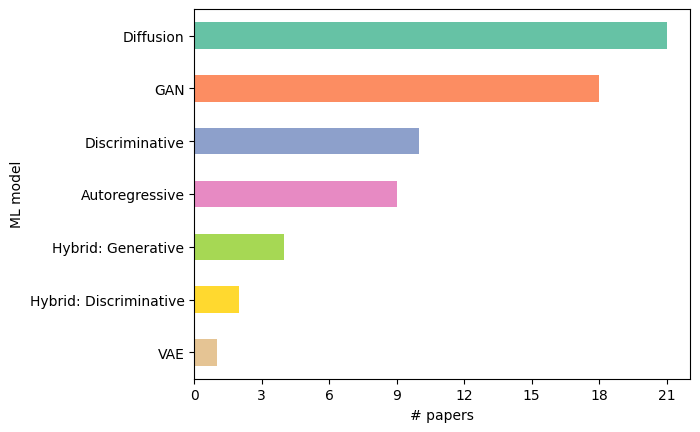

In [93]:
plot_model(df_model)

In [169]:
# plot_discriminative_vs_generative(df_model)

# PRE PROCESSING

In [94]:
def _split_levels(x):
    if ':' in x:
        l1, l2 = x.split(':', 1)
        return pd.Series([l1.strip(), l2.strip()])
    else:
        return pd.Series([x.strip(), None])


def two_level_barh(df, col, xlabel=None, ylabel=None):

    df[f"M_{col}"] = df[col].apply(lambda x: x.split(", "))

    exploded = df[f"M_{col}"].explode()
    exploded = exploded.apply(_split_levels)
    exploded.columns = ['Level1', 'Level2']

    # exploded['Level2'] = exploded['Level2'].fillna('Absent')
    exploded = exploded[exploded["Level1"] != "Absent"]
    # print(exploded)

    counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
    totals = counts.sum(axis=1)
    counts = counts.loc[totals.sort_values(ascending=True).index]
    
    # cmap = plt.cm.Set2
    # num_colors = len(counts.index)
    # colors = [
    #     cmap(i / num_colors) for i in range(num_colors)
    # ]

    ax = counts.plot(
        kind='barh',
        stacked=True,
        rot=0,
        # color=colors,
        # figsize=(2.5, 5)
    )

    if xlabel is not None:
        plt.xlabel(xlabel)
    if ylabel is not None:
        plt.ylabel(ylabel)

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    return ax

<Axes: xlabel='# papers', ylabel='(a) Pre-processing technique'>

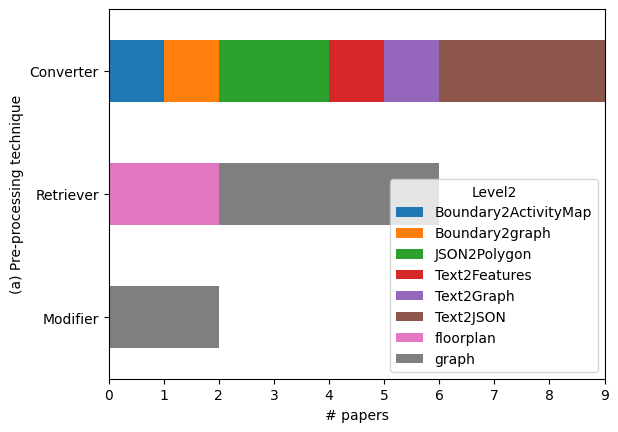

In [95]:
two_level_barh(df_model, "Pre processing outside generative model", xlabel="# papers", ylabel="(a) Pre-processing technique")

# POST PROCESSING

In [343]:
def plot_postprocessing(df_model):
    df_model["postprocessing"] = df_model["Post processing outside generative model"].apply(lambda x: x.split(", "))
    counts = df_model["postprocessing"].explode().value_counts(ascending=True)
    counts = counts.drop("Absent")

    # cmap = plt.cm.tab20
    cmap = plt.cm.tab20c
    # cmap = plt.cm.Set3
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    ax = counts.plot(
        kind="bar", 
        xlabel="# papers", 
        ylabel="(b) Post-processing technique",
        color=colors,
        # figsize=(2.5, 5),
        rot=0,

    )

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    return ax

<Axes: xlabel='# papers', ylabel='(b) Post-processing technique'>

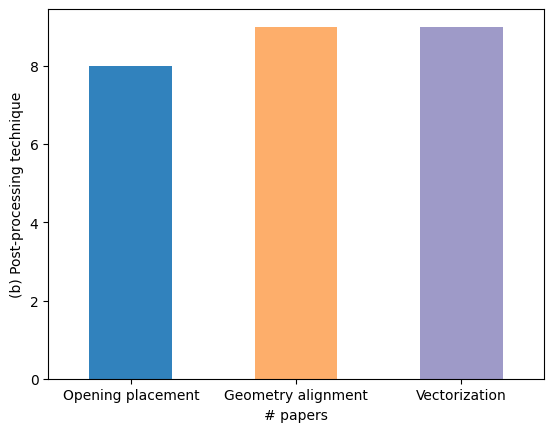

In [344]:
plot_postprocessing(df_model)

# PRE POST

In [346]:
def plot_pre_post_processing(df_model):

    fig, ax = plt.subplots(1, 2, sharey=True, figsize=(10, 5))

    col = "Pre processing outside generative model"
    df_model[f"M_{col}"] = df_model[col].apply(lambda x: x.split(", "))

    exploded = df_model[f"M_{col}"].explode()
    exploded = exploded.apply(_split_levels)
    exploded.columns = ['Level1', 'Level2']
    exploded = exploded[exploded["Level1"] != "Absent"]

    counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
    totals = counts.sum(axis=1)
    counts = counts.loc[totals.sort_values(ascending=True).index]

    # cmap = plt.cm.Set2
    # num_colors = len(counts.index)
    # colors = [
    #     cmap(i / num_colors) for i in range(num_colors)
    # ]

    counts.plot(
        kind='bar',
        stacked=True,
        rot=45,
        ax=ax[0]
    )

    ax[0].set_ylim(
        0,
        10 * 1,
    )
    ax[0].set_xlabel("")
    ax[0].set_ylabel("# papers")
    ax[0].set_title("(a) Pre-processing")

    df_model["postprocessing"] = df_model["Post processing outside generative model"].apply(lambda x: x.split(", "))
    counts = df_model["postprocessing"].explode().value_counts(ascending=True)
    counts = counts.drop("Absent")

    # cmap = plt.cm.tab20
    cmap = plt.cm.tab20c
    # cmap = plt.cm.Set3
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="bar", 
        color=colors,
        rot=45,
        ax=ax[1]
    )

    ax[1].set_ylim(
        0,
        10 * 1,
    )
    ax[1].set_xlabel("")
    ax[1].set_ylabel("# papers")
    ax[1].set_title("(b) Post-processing")



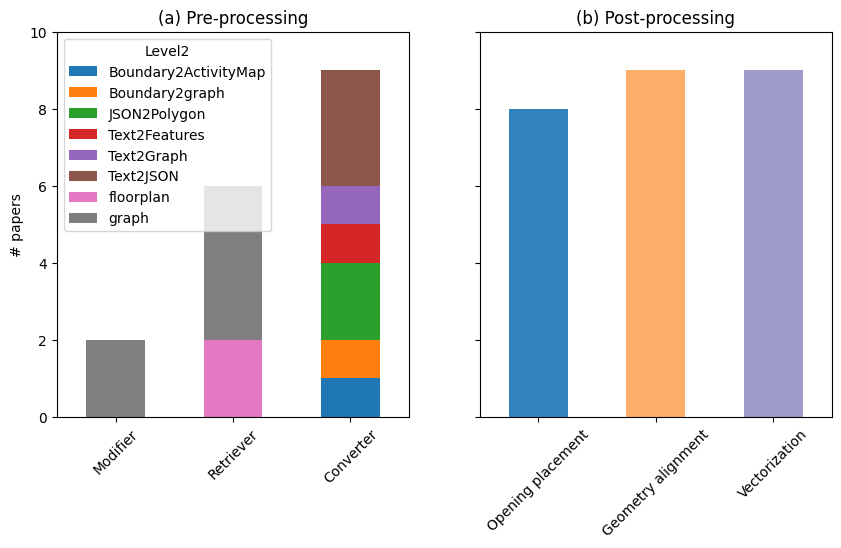

In [347]:
plot_pre_post_processing(df_model)

# INPUT

In [24]:
def preprocess_input(df_model):
    df_model["input"] = df_model["Neural Input (modality: semantics)"].apply(lambda x: set(x.split(", ")))
    df_model["input_modality"] = df_model["input"].apply(lambda x: set(i.split(": ")[0] for i in x))
    df_model["input_content"] = df_model["input"].apply(lambda x: set(i.split(": ")[1] for i in x if i != "Absent")) ### to check later !!!
    return df_model


def plot_input_modality(df_model):

    counts = df_model["input_modality"].explode().value_counts(ascending=True)

    cmap = plt.cm.tab20
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Input modality",
        color=colors,
    )


def plot_input_content(df_model):

    counts = df_model["input_content"].explode().value_counts(ascending=True)

    cmap = plt.cm.tab20
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Input content",
        color=colors,
    )


def get_csv_modality_content(df_model):
    levels = df_model["input"].explode().str.split(':', n=1, expand=True)
    levels.columns = ['level1', 'level2']

    # Clean whitespace
    levels = levels.apply(lambda col: col.str.strip())

    # Count co-occurrences
    counts = (
        levels
        .groupby(['level1', 'level2'])
        .size()
        .reset_index(name='count')
    )

    # Export
    counts.to_csv("data/results/input_modality_content.csv", index=False)


def plot_sankey_input(df_model):

    get_csv_modality_content(df_model)

    df_coocurence = pd.read_csv("data/results/input_modality_content.csv")

    # Keep only needed columns
    df_coocurence = df_coocurence[["level1", "level2", "count"]]

    # Optional: remove tiny flows if diagram is too crowded
    # df = df[df["Count"] >= 2]

    sources = df_coocurence["level1"].astype(str)
    targets = df_coocurence["level2"].astype(str)
    values = df_coocurence["count"]

    # Create unique node list
    nodes = pd.Index(pd.concat([sources, targets]).unique())

    # Map labels to numeric IDs
    source_ids = sources.map(nodes.get_loc)
    target_ids = targets.map(nodes.get_loc)

    fig = go.Figure(data=[go.Sankey(
        node=dict(
            label=nodes.tolist(),
            pad=15,
            thickness=18
        ),
        link=dict(
            source=source_ids,
            target=target_ids,
            value=values
        )
    )])

    fig.update_layout(
        title_text="Modality → Content",
        font_size=10,
        width=1200,
        height=800
    )

    fig.write_image(
        "data/results/input_modality_content.svg",
        scale=4,
    )


In [16]:
df_model = preprocess_input(df_model)

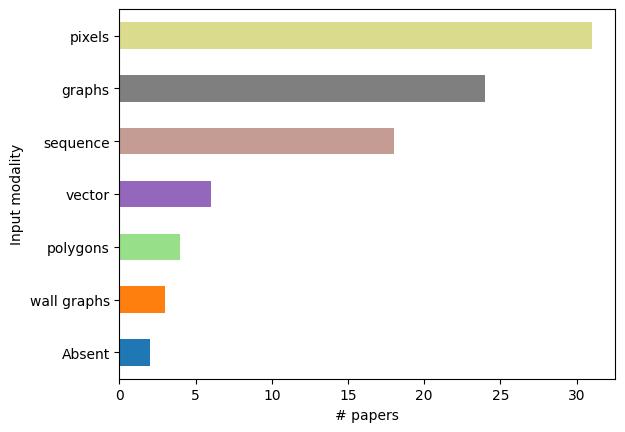

In [17]:
plot_input_modality(df_model)

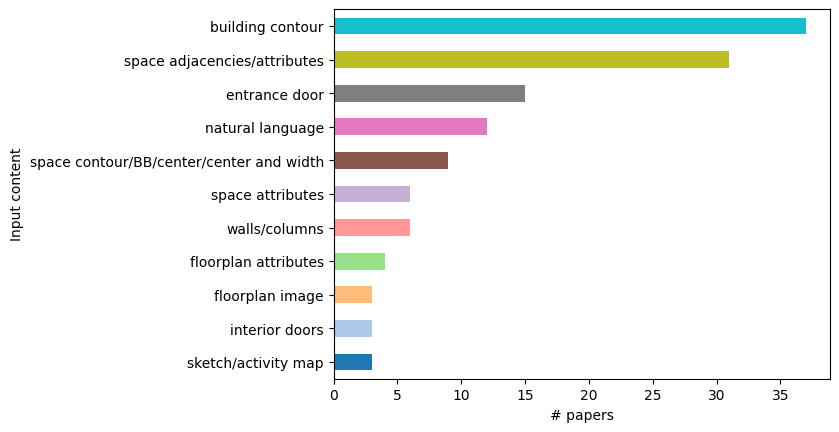

In [18]:
plot_input_content(df_model)

In [25]:
plot_sankey_input(df_model)

# OUTPUT

In [32]:
def plot_output_modality(df_model):
    df_model["output_modality"] = df_model["Neural Output (modality)"].apply(lambda x: x.split(", "))
    counts = df_model["output_modality"].explode().value_counts(ascending=True)

    cmap = plt.cm.Set3
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Output modality",
        color=colors,
    )



def plot_output_content(df_model):
    df_model["output_content"] = df_model["Ultimate Output semantics"].apply(lambda x: set(x.split(", ")))
    counts = df_model["output_content"].explode().value_counts(ascending=True)

    cmap = plt.cm.Set3
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Output content",
        color=colors,
    )


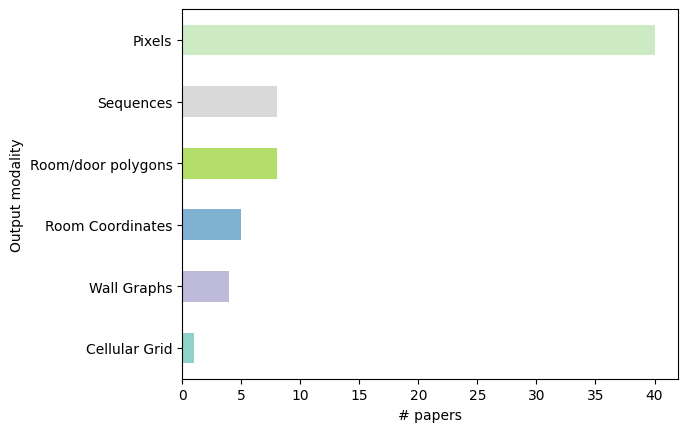

In [31]:
plot_output_modality(df_model)

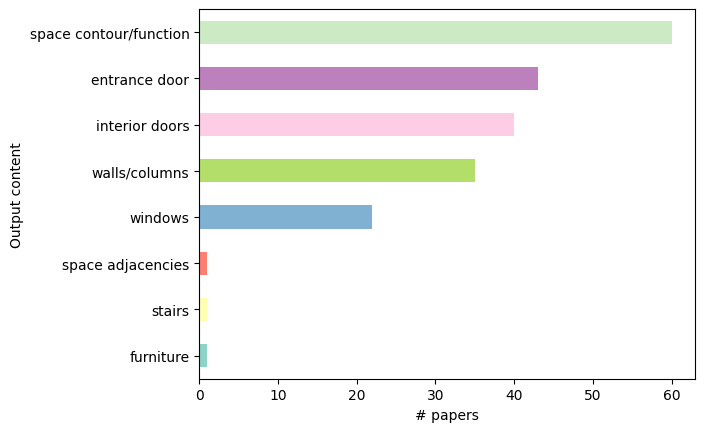

In [33]:
plot_output_content(df_model)

# INPUT-OUTPUT

In [ ]:
///

# *FULL DATASET COLUMNS*

# DATASET

In [10]:
def merge_datasets(x):
    groups = ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"]
    return x if x in groups else "other dataset"


def plot_dataset_per_year(df):

    df["dataset"] = df["Dataset"].apply(lambda x: x.split(", "))

    dataset_exploded = df.explode("dataset")
    dataset_exploded["dataset_grouped"] = dataset_exploded["dataset"].apply(merge_datasets)

    counts = (
        dataset_exploded
        .groupby(['Year', 'dataset_grouped'])
        .size()
        .unstack(fill_value=0)
    )
    y_lim = counts.values.max()*2

    totals = counts.sum(axis=0)
    sorted_counts = (
        totals
        .sort_values(ascending=False)
        .index
    )
    counts = counts[sorted_counts]
    counts.columns = [
        f"{publisher} ({totals[publisher]})"
        for publisher in counts.columns
    ]

    # cmap = plt.cm.Set3
    cmap = plt.cm.tab20c
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    ax = counts.plot(
        kind='bar',
        stacked=True,
        ylabel='# papers',
        color=colors,
        # figsize=(12,6)
    )
    ax.tick_params(axis='x', rotation=0)
    # ax.grid(axis='y')
    ax.set_ylim(
        0,
        y_lim * 1.1,
    )

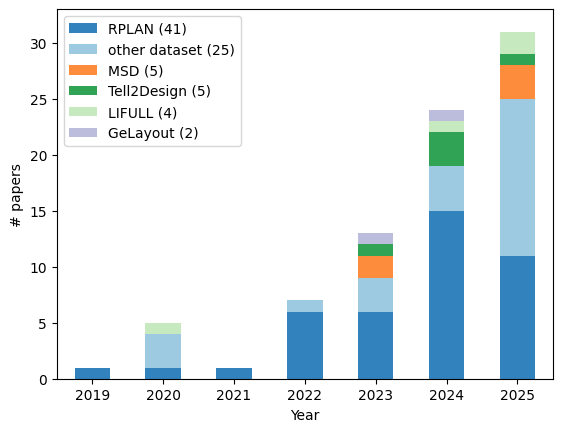

In [10]:
plot_dataset_per_year(df)

# GENERALIZABILITY

In [18]:
def generalizability_barh(df, col, xlabel=None, ylabel=None):

    df[f"M_{col}"] = df[col].apply(lambda x: x.split(", "))

    exploded = df[f"M_{col}"].explode()
    exploded = exploded.apply(_split_levels)
    exploded.columns = ['Level1', 'Level2']

    # exploded['Level2'] = exploded['Level2'].fillna('Absent')
    exploded = exploded[exploded["Level1"] != "Absent"]
    # print(exploded)

    counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
    totals = counts.sum(axis=1)
    counts = counts.loc[totals.sort_values(ascending=True).index]
    
    # cmap = plt.cm.Set2
    # num_colors = len(counts.index)
    # colors = [
    #     cmap(i / num_colors) for i in range(num_colors)
    # ]

    ax = counts.plot(
        kind='barh',
        stacked=True,
        rot=0,
        # color=colors,
        # figsize=(2.5, 5)
    )
    
    ax.legend(
        loc='center left',
        bbox_to_anchor=(1, 0.5)
    )
    
    if xlabel is not None:
        plt.xlabel(xlabel)
    if ylabel is not None:
        plt.ylabel(ylabel)

    ax.set_xlim(
        0,
        9,
    )

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    return ax

<Axes: xlabel='# papers', ylabel='Generalizability/Memorization'>

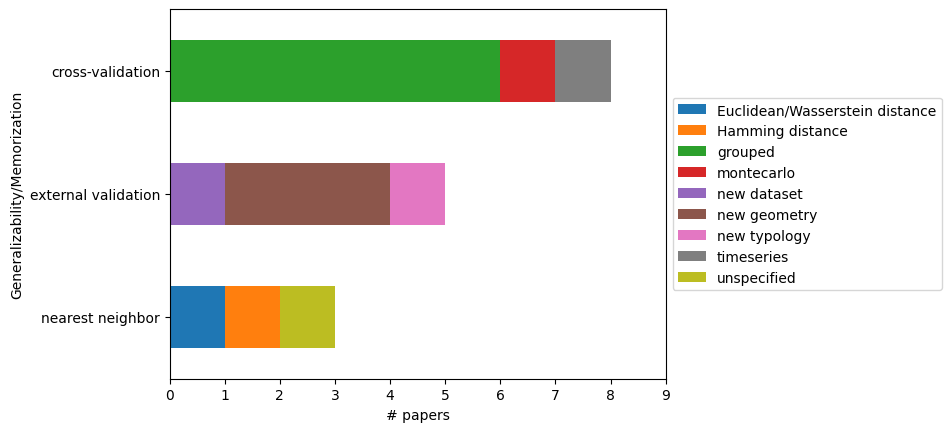

In [19]:
generalizability_barh(df, "Generalizability", xlabel="# papers", ylabel="Generalizability/Memorization")

# USER STUDIES

In [29]:
counts = df["user_studies"].explode().value_counts(ascending=True)
counts


user_studies
Turing test               3
Instruction-following     4
Realism                  17
Intrinsic evaluation     19
Absent                   34
Name: count, dtype: int64

In [33]:
counts.drop("Absent")

user_studies
Turing test               3
Instruction-following     4
Realism                  17
Intrinsic evaluation     19
Name: count, dtype: int64

In [36]:
def plot_user_studies(df):

    df["user_studies"] = df["User Studies"].apply(lambda x: x.split(", "))
    counts = df["user_studies"].explode().value_counts(ascending=True)
    counts = counts.drop("Absent")
    
    cmap = plt.cm.Set3
    # cmap = plt.cm.Pastel1
    # cmap = plt.cm.tab20b
    
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    ax = counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="User study type",
        color=colors,
    )

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

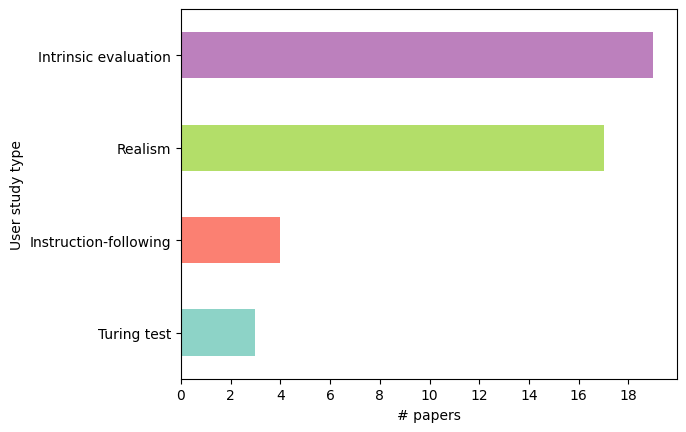

: 

In [ ]:
plot_user_studies(df)

# METRICS

### two-level bars

In [67]:
# two_level_barh(df, "AF: Intrinsic", xlabel="# papers", ylabel="AF: Intrinsic")

In [65]:
# two_level_barh(df, "AF: Normative compliance", xlabel="# papers", ylabel="AF: Normative compliance")

In [66]:
# two_level_barh(df, "AF: instruction-following", xlabel="# papers", ylabel="AF: instruction-following")

In [51]:
# two_level_barh(df, "AF: similarity", xlabel="# papers", ylabel="AF: similarity")

### Num papers per metric group

In [ ]:
def num_papers_per_metric_group(df):
    cols = [
        "AF: similarity",
        "AF: instruction-following",
        "AF: Normative compliance",
        "AF; Intrinsic",
    ]


df["AF: Intrinsic"][df["AF: Intrinsic"] != "Absent"].shape[0]

9

### Num papers per unique metric

In [104]:
"""
Processing values
"""
def _process_similarity(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Embeddings" in metric:
        return "Embeddings" 
    elif "Graphs" in metric:
        return "Graphs"
    elif "Attributes" in metric:
        return "Attributes"
    elif ("IoU" in metric) or ("Chamfer" in metric):
        return "Regions"
    else:
        return "Pixels"
    

def _process_instruction_following(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Embeddings" in metric:
        return "Embeddings" 
    elif "Graphs" in metric:
        return "Graphs"
    elif "Attributes" in metric:
        return "Attributes"
    elif "Boundary":
        return "Regions"
    else:
        raise ValueError


def _process_normative_compliance(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Graphs" in metric:
        return "Graphs"
    elif "Attributes" in metric:
        return "Attributes"
    else:
        raise ValueError
    

def _process_intrinsic(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Embeddings" in metric:
        return "Embeddings" 
    elif "Regions" in metric:
        return "Regions"
    elif "Attributes" in metric:
        return "Attributes"
    else:
        raise ValueError


"""
Num papers per unique metric
"""
from functools import partial

def _flag_singles(lst, singles):
    if len(set(lst) & set(singles)) > 0:
        return 1
    return 0
    

def num_papers_per_metric(df, src_col, res_col):

    df[res_col] = df[src_col].apply(lambda x: x.split(", "))

    exploded = df[res_col].explode()
    unique = exploded.value_counts()
    singles = unique[unique == 1].index.to_list()
    plurals = unique[unique > 1]

    count_singles = df[res_col].apply(partial(_flag_singles, singles=singles)).sum() ### 
    plurals["other_metrics"] = count_singles
    plurals = plurals.drop("Absent")
    plurals = plurals.sort_values(ascending=False)

    return plurals

In [ ]:
similarity_counts = num_papers_per_metric(df, "AF: similarity", "similarity")
instruction_counts = num_papers_per_metric(df, "AF: instruction-following", "instruction_following")
normative_counts = num_papers_per_metric(df, "AF: Normative compliance", "normative_compliance")
intrinsic_counts = num_papers_per_metric(df, "AF: Intrinsic", "intrinsic")

In [145]:
intrinsic_counts

intrinsic
other_metrics     7
Embeddings: IS    2
Name: count, dtype: int64

In [142]:
concatenated = pd.concat(
    [
        similarity_counts,
        instruction_counts,
        normative_counts, 
        intrinsic_counts,
    ],
    axis=0
)

concatenated

Embeddings: FID                    39
IoU-based                          22
SSIM                               11
PSNR                               11
other_metrics                       7
Graphs: GED                         5
Attributes: room statistics         4
MSE                                 3
MAE                                 3
Embeddings: real/fake               3
Embeddings: KID                     3
Embeddings: LPIPS                   2
Graphs: Graph Compatibility         2
Graphs: GED                        17
Attributes: Prompt Consistency      5
Boundary: IoU                       3
other_metrics                       2
Attributes: EUI                     3
other_metrics                       3
Attributes: accessibility check     2
other_metrics                       7
Embeddings: IS                      2
Name: count, dtype: int64

<Axes: >

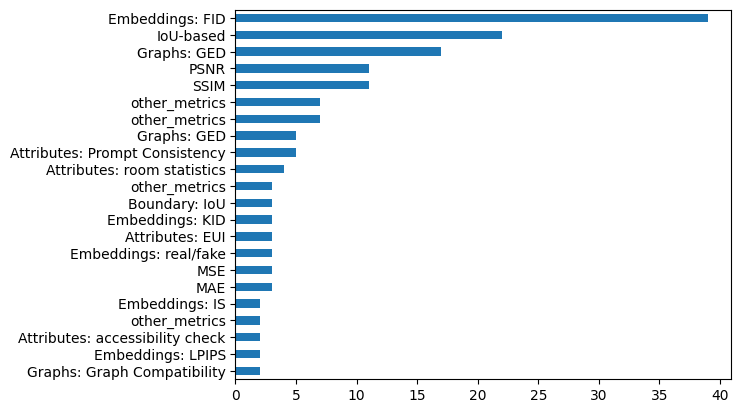

In [144]:
concatenated.sort_values(ascending=True).plot(kind="barh")

In [ ]:
def grouped_series(s1, s2, s3, s4):

    df_plot = pd.concat([s1, s2, s3, s4], axis=1)

    df_plot.columns = [
        "Series 1",
        "Series 2",
        "Series 3",
        "Series 4"
    ]

    df_plot = df_plot.fillna(0)
    
    colors = {
        "Series 1": "#4E79A7",
        "Series 2": "#F28E2B",
        "Series 3": "#59A14F",
        "Series 4": "#E15759"
    }

    ax = df_plot.plot(
        kind="barh",
        color=[colors[col] for col in df_plot.columns],
        figsize=(9, 7)
    )

    ax.set_xlabel("# papers")
    ax.grid(axis="x", linestyle="--", alpha=0.4)

    ax.legend(
        title="Series",
        # loc="center left",
        # bbox_to_anchor=(1.02, 0.5)
    )

    plt.tight_layout()
    plt.show()

In [134]:
grouped_series(
    # similarity_counts.sort_values(ascending=True), 
    # instruction_counts.sort_values(ascending=True), 
    # normative_counts.sort_values(ascending=True), 
    # intrinsic_counts.sort_values(ascending=True),
)

TypeError: grouped_series() missing 4 required positional arguments: 's1', 's2', 's3', and 's4'

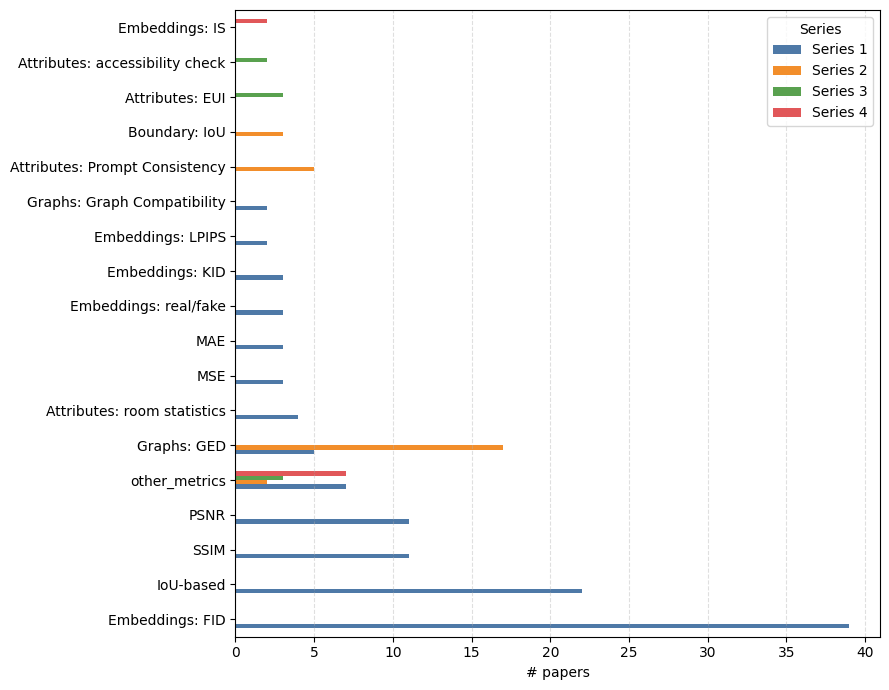

In [ ]:
grouped_series(
    similarity_counts,
    instruction_counts,
    normative_counts, 
    intrinsic_counts,
)

In [130]:
instruction_counts 

instruction_following
Graphs: GED                       17
Attributes: Prompt Consistency     5
Boundary: IoU                      3
other_metrics                      2
Name: count, dtype: int64

In [129]:
similarity_counts

similarity
Embeddings: FID                39
IoU-based                      22
SSIM                           11
PSNR                           11
other_metrics                   7
Graphs: GED                     5
Attributes: room statistics     4
MSE                             3
MAE                             3
Embeddings: real/fake           3
Embeddings: KID                 3
Embeddings: LPIPS               2
Graphs: Graph Compatibility     2
Name: count, dtype: int64

In [121]:
# fig, ax = plt.subplots(1, 2)

# similarity_counts.sort_values(ascending=True).plot(kind="barh", ax=ax[0])
# instruction_counts.sort_values(ascending=True).plot(kind="barh", ax=ax[1])

# plt.plot()

<Axes: ylabel='similarity'>

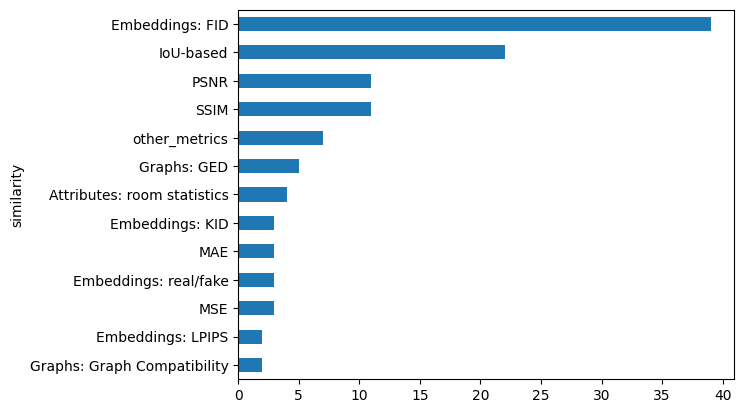

In [123]:
similarity_counts.sort_values(ascending=True).plot(kind="barh")

<Axes: ylabel='instruction_following'>

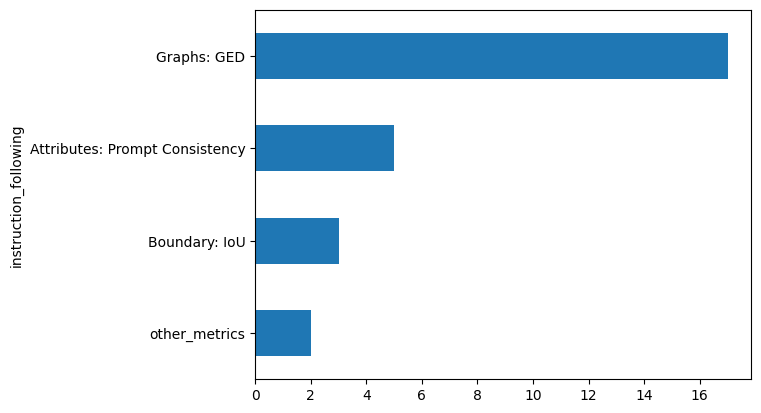

In [124]:
instruction_counts.sort_values(ascending=True).plot(kind="barh")

<Axes: ylabel='normative_compliance'>

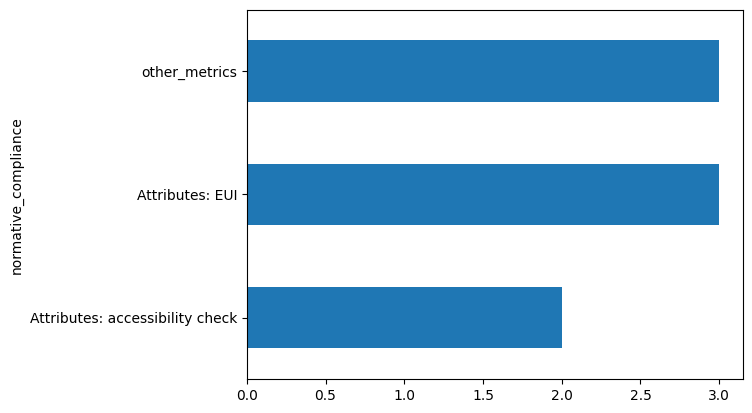

In [125]:
normative_counts.sort_values(ascending=True).plot(kind="barh")

<Axes: ylabel='intrinsic'>

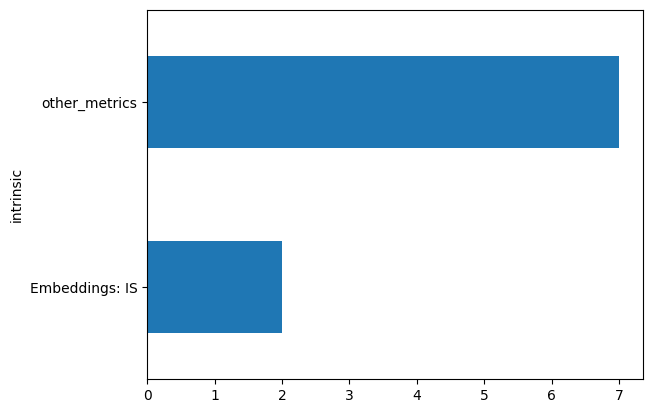

In [126]:
intrinsic_counts.sort_values(ascending=True).plot(kind="barh")

<Axes: ylabel='similarity'>

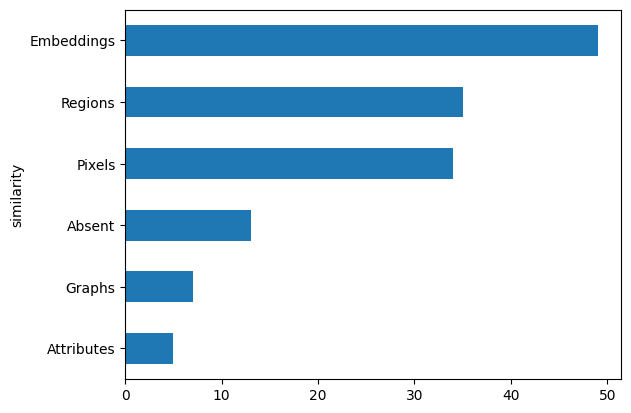

In [16]:
def process_similarity(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Embeddings" in metric:
        return "Embeddings" 
    elif "Graphs" in metric:
        return "Graphs"
    elif "Attributes" in metric:
        return "Attributes"
    elif ("IoU" in metric) or ("Chamfer" in metric):
        return "Regions"
    else:
        return "Pixels"
    

df["similarity"] = df["AF: similarity"].apply(lambda x: x.split(", "))
exploded_similarity = df["similarity"].explode().apply(process_similarity)
exploded_similarity.value_counts(ascending=True).plot(kind="barh")

<Axes: ylabel='instruction_f'>

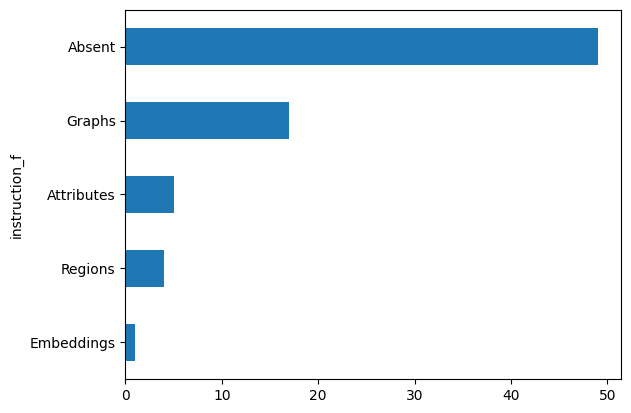

In [17]:
def process_instruction_following(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Embeddings" in metric:
        return "Embeddings" 
    elif "Graphs" in metric:
        return "Graphs"
    elif "Attributes" in metric:
        return "Attributes"
    elif "Boundary":
        return "Regions"
    else:
        raise ValueError
    

df["instruction_f"] = df["AF: instruction-following"].apply(lambda x: x.split(", "))
exploded_instruction_f = df["instruction_f"].explode().apply(process_instruction_following)
exploded_instruction_f.value_counts(ascending=True).plot(kind="barh")

<Axes: ylabel='normative_c'>

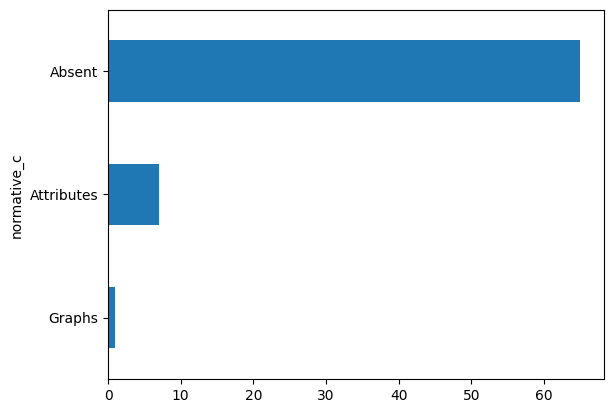

In [18]:
def process_normative_compliance(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Graphs" in metric:
        return "Graphs"
    elif "Attributes" in metric:
        return "Attributes"
    else:
        raise ValueError
    

df["normative_c"] = df["AF: Normative compliance"].apply(lambda x: x.split(", "))
exploded_normative_c = df["normative_c"].explode().apply(process_normative_compliance)
exploded_normative_c.value_counts(ascending=True).plot(kind="barh")

In [63]:
from functools import partial


def _process_intrinsic(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Embeddings" in metric:
        return "Embeddings" 
    elif "Regions" in metric:
        return "Regions"
    elif "Attributes" in metric:
        return "Attributes"
    else:
        raise ValueError
    

def _flag_singles(lst, singles):
    if len(set(lst) & set(singles)) > 0:
        return 1
    return 0
    


def get_intrinsic_exploded(df):

    df["intrinsic"] = df["AF: Intrinsic"].apply(lambda x: x.split(", "))
    exploded = df["intrinsic"].explode()
    unique = exploded.value_counts()
    singles = unique[unique == 1].index.to_list()
    plurals = unique[unique > 1]

    count_singles = df["intrinsic"].apply(partial(_flag_singles, singles=singles)).sum()
    plurals["other_metrics"] = count_singles
    plurals = plurals.drop("Absent")
    return plurals

<Axes: ylabel='intrinsic'>

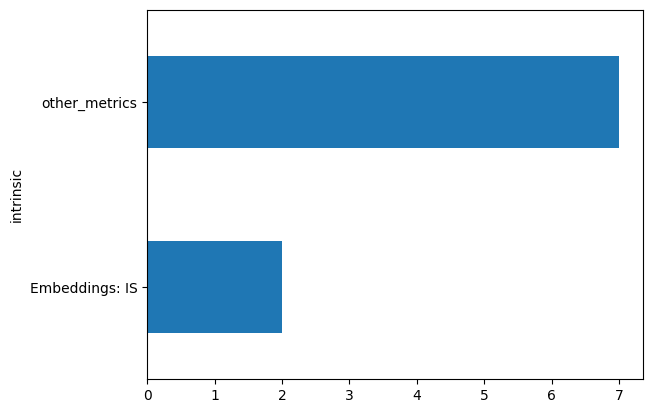

In [64]:
plurals_intrinsic = get_intrinsic_exploded(df)
plurals_intrinsic.plot(kind="barh")

In [49]:
exploded = df["intrinsic"].explode().apply(_process_intrinsic)
exploded

0     Attributes
0     Attributes
1         Absent
2         Absent
3         Absent
         ...    
67        Absent
68        Absent
69        Absent
70       Regions
71    Embeddings
Name: intrinsic, Length: 76, dtype: str

In [ ]:
exploded = df["intrinsic"].explode().apply(_process_intrinsic)
unique = exploded.value_counts()
singles = unique[unique == 1].index.to_list()

exploded_intrinsic = df["intrinsic"].explode().apply(_process_intrinsic)

In [ ]:
intrinsic_unique = df["intrinsic"].value_counts()

intrinsic
[Absent]                                                                                                                                   63
[Embeddings: IS]                                                                                                                            2
[Attributes: RAI, Attributes: Space Property Proportion]                                                                                    1
[Attributes: Shortest-path sanity, Attributes: Room count distribution, Attributes: Min/Max Area ratio, Attributes: Connectivity Ratio]     1
[Regions: Vectorization Success Rate]                                                                                                       1
[Attributes: Self-Consistency]                                                                                                              1
[Regions: Geometric validity]                                                                                                             

In [37]:
intrinsic_unique = df["intrinsic"].explode().value_counts()
intrinsic_unique

intrinsic
Absent                                   63
Embeddings: IS                            2
Attributes: RAI                           1
Attributes: Space Property Proportion     1
Attributes: Shortest-path sanity          1
Attributes: Room count distribution       1
Attributes: Min/Max Area ratio            1
Attributes: Connectivity Ratio            1
Regions: Vectorization Success Rate       1
Attributes: Self-Consistency              1
Regions: Geometric validity               1
Attributes: ARS                           1
Regions: Percent of isolated rooms        1
Name: count, dtype: int64

In [51]:
intrinsic_unique["OTHERS"] = 100

In [52]:
intrinsic_unique

intrinsic
Absent                                    63
Embeddings: IS                             2
Attributes: RAI                            1
Attributes: Space Property Proportion      1
Attributes: Shortest-path sanity           1
Attributes: Room count distribution        1
Attributes: Min/Max Area ratio             1
Attributes: Connectivity Ratio             1
Regions: Vectorization Success Rate        1
Attributes: Self-Consistency               1
Regions: Geometric validity                1
Attributes: ARS                            1
Regions: Percent of isolated rooms         1
OTHERS                                   100
Name: count, dtype: int64

In [ ]:
intrinsic_unique[intrinsic_unique["intrinsic"]]

In [44]:
intrinsic_unique[intrinsic_unique == 1].index.to_list()

['Attributes: RAI',
 'Attributes: Space Property Proportion',
 'Attributes: Shortest-path sanity',
 'Attributes: Room count distribution',
 'Attributes: Min/Max Area ratio',
 'Attributes: Connectivity Ratio',
 'Regions: Vectorization Success Rate',
 'Attributes: Self-Consistency',
 'Regions: Geometric validity',
 'Attributes: ARS',
 'Regions: Percent of isolated rooms']

In [45]:
singles = intrinsic_unique[intrinsic_unique == 1].index.to_list()
singles

['Attributes: RAI',
 'Attributes: Space Property Proportion',
 'Attributes: Shortest-path sanity',
 'Attributes: Room count distribution',
 'Attributes: Min/Max Area ratio',
 'Attributes: Connectivity Ratio',
 'Regions: Vectorization Success Rate',
 'Attributes: Self-Consistency',
 'Regions: Geometric validity',
 'Attributes: ARS',
 'Regions: Percent of isolated rooms']

In [46]:
plurals = intrinsic_unique[intrinsic_unique > 1].index.to_list()
plurals

['Absent', 'Embeddings: IS']

In [ ]:
df["normative_c"].explode().value_counts()

normative_c
Absent                                65
Attributes: EUI                        3
Attributes: accessibility check        2
Graphs: adjacency violations           1
Attributes: AEC                        1
Attributes: functional rationality     1
Name: count, dtype: int64

In [25]:
df["instruction_f"].explode().value_counts()

instruction_f
Absent                            49
Graphs: GED                       17
Attributes: Prompt Consistency     5
Boundary: IoU                      3
Boundary: Compatibility            1
Embeddings: CLIP Score             1
Name: count, dtype: int64

In [36]:
def check_intruction_f(lst):
    others = ["Embeddings: CLIP Score", "Boundary: Compatibility"]
    if len(set(lst) & set(others)) > 0:
        return 1
    return 0
    
df["instruction_f"].apply(check_intruction_f).sum()

np.int64(2)

In [34]:
df["instruction_f"].value_counts()

instruction_f
[Absent]                                         49
[Graphs: GED]                                    13
[Attributes: Prompt Consistency]                  4
[Graphs: GED, Boundary: IoU]                      1
[Boundary: IoU]                                   1
[Boundary: IoU, Graphs: GED]                      1
[Graphs: GED, Boundary: Compatibility]            1
[Embeddings: CLIP Score]                          1
[Graphs: GED, Attributes: Prompt Consistency]     1
Name: count, dtype: int64

<Axes: ylabel='similarity'>

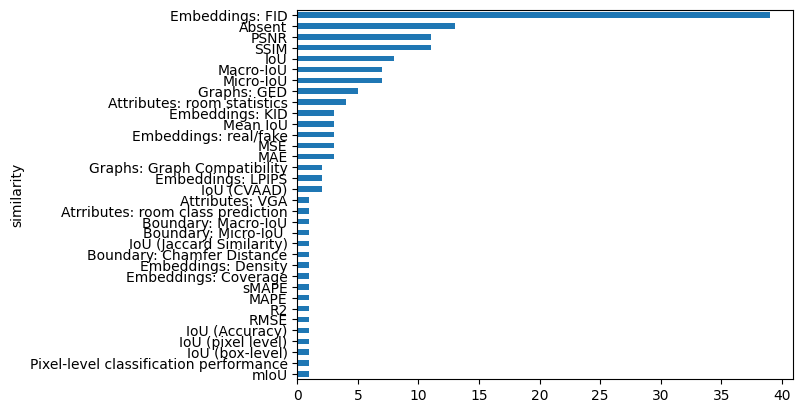

In [28]:
df["similarity"].explode().value_counts(ascending=True).plot(kind="barh")

<Axes: ylabel='instruction_f'>

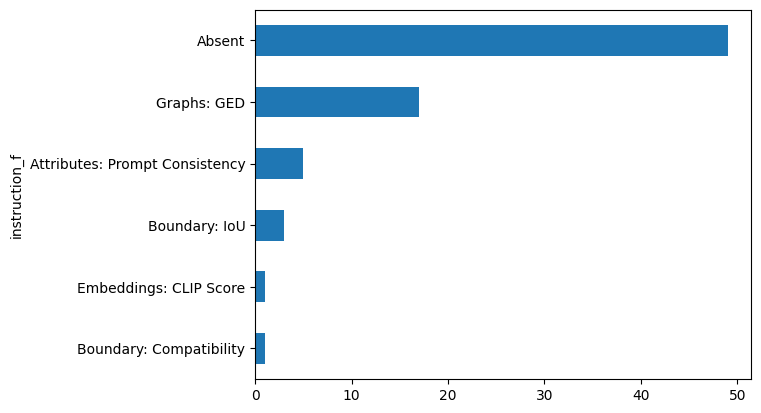

In [29]:
df["instruction_f"].explode().value_counts(ascending=True).plot(kind="barh")

<Axes: ylabel='normative_c'>

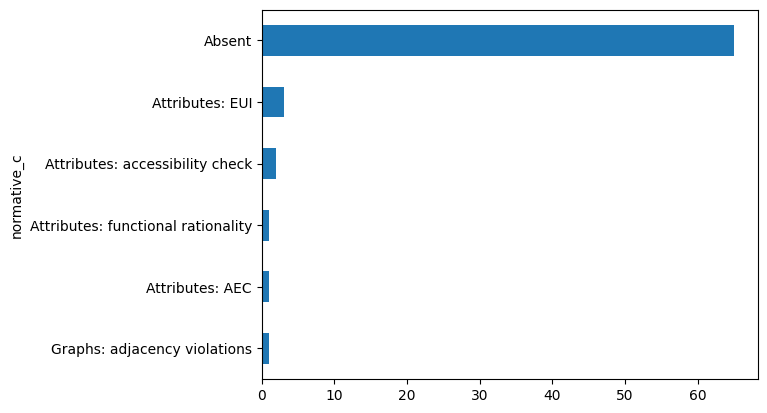

In [30]:
df["normative_c"].explode().value_counts(ascending=True).plot(kind="barh")

<Axes: ylabel='intrinsic'>

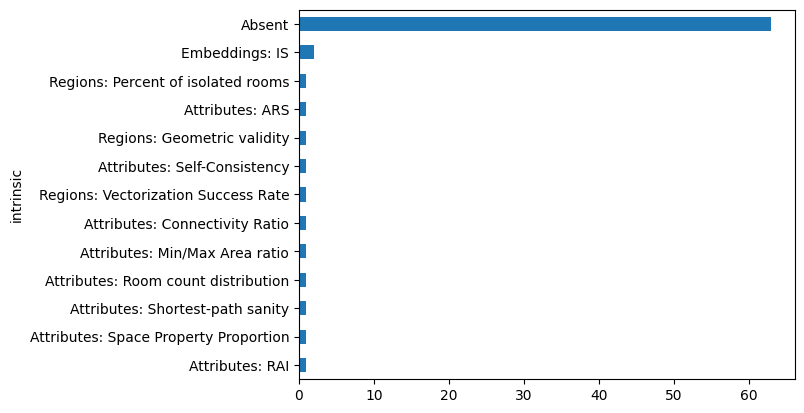

In [31]:
df["intrinsic"].explode().value_counts(ascending=True).plot(kind="barh")